# Projet 6 Analyser le profil des vins : Réduction de la dimensionnalité avec l'ACP
## Problématique métier
Une entreprise souhaite identifier les axes clés de différenciation entre
ses clients afin de mieux personnaliser ses offres. Ce projet explore un
ensemble de données sur la qualité du vin pour identifier ces
différences.
Compétences à acquérir
- Réduction de dimensionnalité : Utilisation de l'ACP pour les
données continues .
- Visualisation : Réduction des dimensions pour visualiser les
données en 2D et 3D.
- Interprétation des résultats : Comprendre les axes discriminants et
les groupes significatifs.
Base de données

## Chargement et exploration des données

In [5]:
# Importation des bibliothèques nécessaires pour les analyses
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Importation des deux bases de données
vin_red = pd.read_csv("projet6-vin-red.csv", sep = ';')
vin_white = pd.read_csv("projet6-vin-white.csv", sep = ';')
print("===="*8," Affichage de la base du vin rouge","===="*8)
print(vin_red)
print(" ")
print("===="*8," Affichage de la base du vin blanc","===="*8)
print(vin_white)

# Fusion des deux bases de données
vin_red['type'] = 'red'
vin_white['type'] = 'white'

df = pd.concat([vin_red,vin_white], ignore_index = True)
print(" ")
print("===="*8," Affichage de la base fusionée","===="*8)
df.head()

================================  Affichage de la base du vin rouge ================================
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598    

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [6]:
# information complementaire sur la base de données
print(df.shape)
print(df.info())

# vérification de valeur manquante par colonne
print(df.isnull().sum())
df.dtypes

(6497, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
None
fixed acidity           0
volatile acidity     

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
type                     object
dtype: object

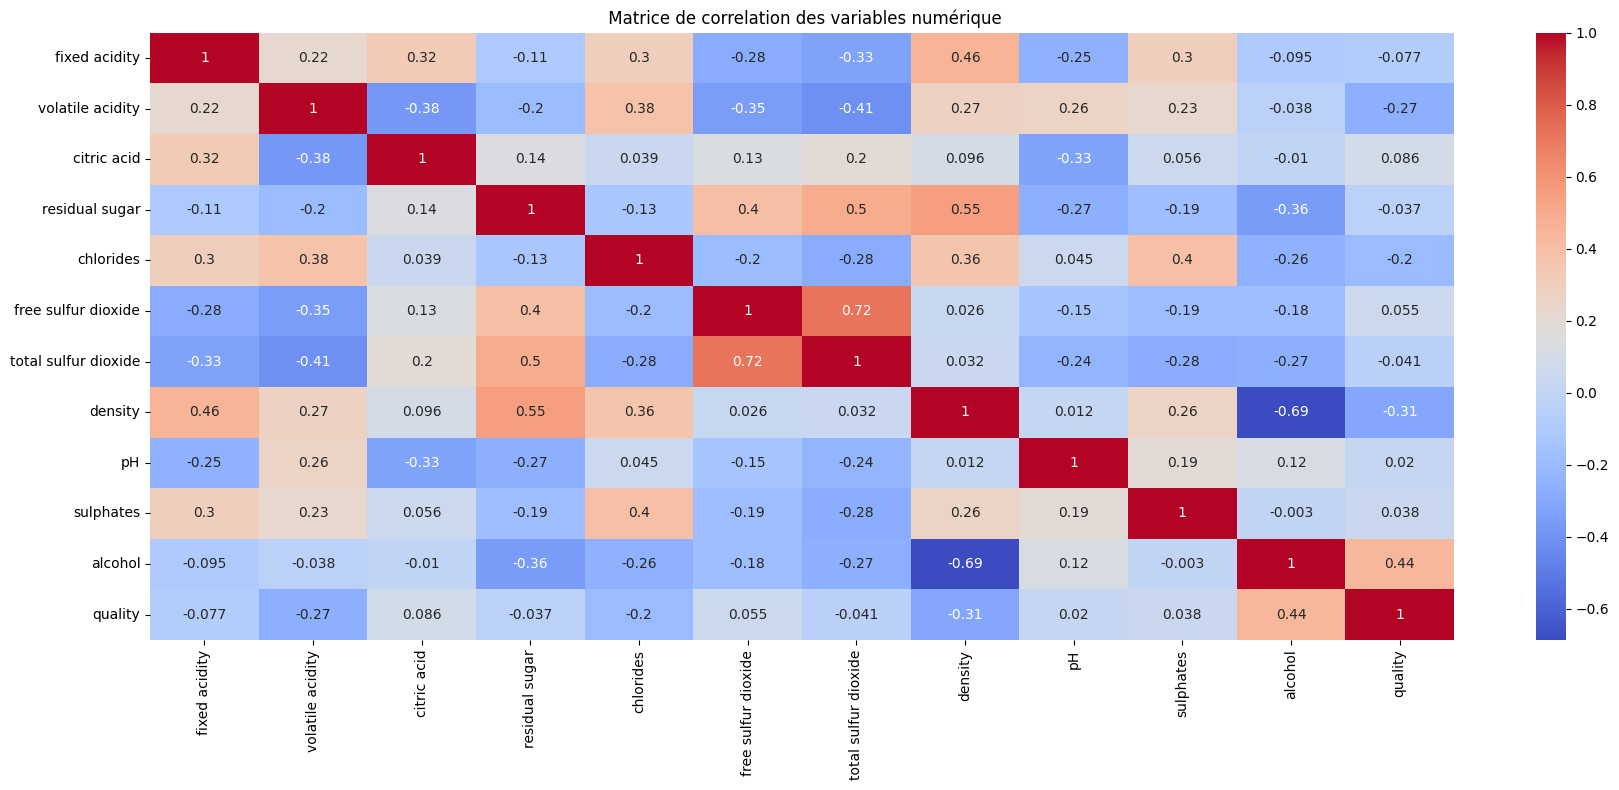

In [7]:
"""
    Nous allons faire un heamap pour vérifier les correlations entre 
    les variables numériques parce que s'il n'y a pas de correlation 
    netre les différentes variables alors l' ACP sera unitile
"""
# Selection des variables numériques
num_cols = df.select_dtypes(include = np.number).columns
num_cols
# Headmap
corr = df[num_cols].corr()
plt.figure(figsize=(18,8))
sns.heatmap(corr, annot = True, cmap = 'coolwarm')
plt.title(" Matrice de correlation des variables numérique")
plt.tight_layout()

## Preprocessing des données

In [9]:
# Separation feature et cible
X = df.drop(columns = ['quality'])
y = df['quality']

# Encodage du type (rouge ou blanc) car l'ACP n'accèpe que les variables numériques
X = pd.get_dummies(X, columns = ['type'], drop_first=True)

# Standarisation des features numériques
scaler = StandardScaler()
X_scaler = scaler.fit_transform(X)

## ACP

In [10]:
pca = PCA()
X_pca = pca.fit_transform(X_scaler)

print(X_pca.shape)
print(pca.explained_variance_ratio_)

(6497, 12)
[0.3174498  0.21072897 0.13012495 0.08090319 0.06031777 0.05112838
 0.04469717 0.04191537 0.02937103 0.02140269 0.00994841 0.00201227]


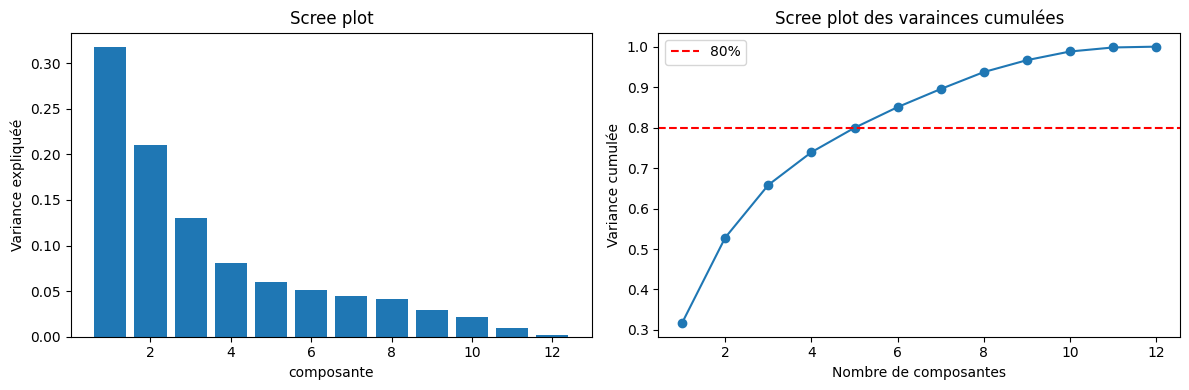

In [11]:
# Réalisation du scree plot pour vérification visuel

cumsum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(1,2,figsize = (12,4))

# Scree plot
ax[0].bar(range(1,13),pca.explained_variance_ratio_)
ax[0].set_xlabel('composante')
ax[0].set_ylabel('Variance expliquéé')
ax[0].set_title('Scree plot')

# Variance cumulée
ax[1].plot(range(1,13),cumsum, marker = 'o' )
ax[1].axhline(0.8, ls='--', c='r', label='80%')
ax[1].set_xlabel('Nombre de composantes')
ax[1].set_ylabel('Variance cumulée')
ax[1].set_title('Scree plot des varainces cumulées')
ax[1].legend()
plt.tight_layout()

In [12]:
# interpretation des composantges via les loadings

loadings = pd.DataFrame(
    pca.components_[:5].T,               # 5 premières composantes
    columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'],
    index=X.columns
)

#print(loadings.round(2))
# Trier par ordre de paticipation sur pc1
print('==='*10, ' Participation sur PC1','==='*10, )
loadings['PC1'].sort_values(key=abs, ascending=False).round(2)

==============================  Participation sur PC1 ==============================


type_white              0.47
total sulfur dioxide    0.41
volatile acidity       -0.36
free sulfur dioxide     0.35
chlorides              -0.30
sulphates              -0.28
fixed acidity          -0.26
residual sugar          0.25
pH                     -0.18
density                -0.14
citric acid             0.11
alcohol                -0.02
Name: PC1, dtype: float64

### Interprétation
PC1 oppose deux profils :

Côté positif  profil "blanc" : SO2 élevé, moins acide, un peu plus sucré

Côté négatif  profil "rouge" : plus acide (volatile + fixed), plus de chlorures et sulphates

PC1 = axe "type de vin" (blanc vs rouge), porté principalement par le SO2 et l'acidité.

Point important : alcohol a un loading quasi nul (-0.02) sur PC1 donc l'alcool n'est pas ce qui différencie les vins sur cet axe.

In [14]:
# Trier par ordre de participation sur PC2
print('==='*10, ' Participation sur PC2','==='*10, )
print(loadings['PC2'].sort_values(key = abs, ascending = False).round(2))

==============================  Participation sur PC2 ==============================
density                 0.56
alcohol                -0.48
residual sugar          0.40
fixed acidity           0.27
chlorides               0.24
citric acid             0.21
pH                     -0.19
total sulfur dioxide    0.19
free sulfur dioxide     0.17
sulphates               0.12
type_white             -0.08
volatile acidity        0.03
Name: PC2, dtype: float64


### Interprétation
PC2 oppose deux profils :

Côté positif vin dense, sucré, peu alcoolisé (vin moelleux / liquoreux)

Côté négatif vin léger, alcoolisé, peu sucré (vin sec / fort en alcool)

PC2 = axe "moelleux vs sec", porté par le trio densité / sucre / alcool.

In [9]:
# Trier par ordre de contribution sur PC3
loadings['PC3'].sort_values(key = abs, ascending = False).round(2)

citric acid             0.59
fixed acidity           0.45
pH                     -0.45
volatile acidity       -0.29
alcohol                 0.25
residual sugar         -0.17
density                -0.16
free sulfur dioxide    -0.16
total sulfur dioxide   -0.13
sulphates               0.09
type_white              0.05
chlorides               0.01
Name: PC3, dtype: float64

### Interprétation
PC3 est un axe d'acidité, mais attention à la nuance :

Côté positif vin riche en acides "nobles" (citrique + fixe), pH bas, peu d'acidité volatile

Côté négatif vin pauvre en acides fixes, plus de volatile

PC3 = axe "fraîcheur / acidité maîtrisée".

Point clé :Nous remarquons que citric acid et fixed acidity vont ensemble (+) tandis que pH va à l'opposé (–).

Nuance importante : volatile acidity et fixed acidity sont deux type d'acidité : 
            Acide fixe/citrique = bon pour le vin (fraîcheur)

Acide volatile = défaut (vinaigre)

In [15]:
# Trier par ordre de contribution sur le PC4
loadings['PC4'].sort_values(key = abs, ascending = False).round(2)


sulphates               0.64
pH                      0.41
free sulfur dioxide     0.36
citric acid             0.27
chlorides               0.24
volatile acidity       -0.22
total sulfur dioxide    0.21
fixed acidity          -0.17
residual sugar         -0.17
alcohol                 0.11
density                -0.07
type_white             -0.02
Name: PC4, dtype: float64

### Interprétation
PC4 est dominé par sulphates (+0.64), très largement au-dessus des autres.

PC4 = axe "sulphates / additifs de conservation".

Nuance : sulphates et SO2 libre montent ensemble  cohérent, ce sont deux additifs liés à la conservation du vin.

Cette composante capte une variance plus faible (8.1%) et traduit surtout une variation de traitement œnologique plutôt qu'un profil sensoriel.

Loading de type_white quasi nul (-0.02) cet axe est indépendant du type rouge/blanc.

In [16]:
# Trier par ordre de contribution sur PC5
loadings['PC5'].sort_values(key = abs, ascending = False).round(2)

chlorides               0.64
pH                     -0.44
residual sugar         -0.36
density                -0.29
alcohol                -0.21
free sulfur dioxide     0.17
citric acid            -0.16
fixed acidity          -0.15
volatile acidity        0.15
total sulfur dioxide    0.14
sulphates              -0.11
type_white              0.08
Name: PC5, dtype: float64

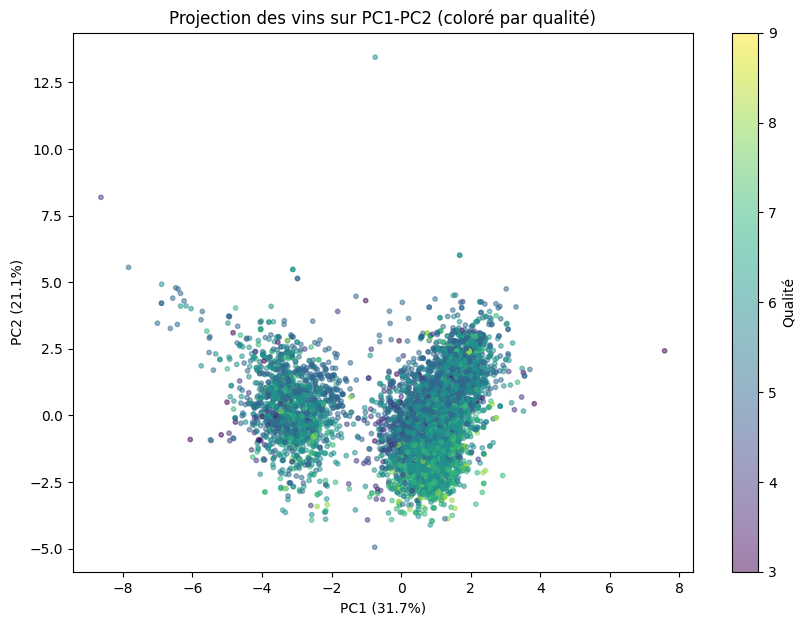

In [18]:
# Visualisation des vins sur PC1 et PC2 coloré par qualité

X_pca_5 = X_pca[:, :5]   # 5 premières composantes seulement

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca_5[:, 0], X_pca_5[:, 1],
    c=y, cmap='viridis', alpha=0.5, s=10
)
plt.colorbar(scatter, label='Qualité')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('Projection des vins sur PC1-PC2 (coloré par qualité)')
plt.show()

### Interprétation métier : 
la qualité n'est pas un axe dominant dans la chimie du vin. Elle dépend de combinaisons plus subtiles (probablement PC3+ ou de relations non linéaires).

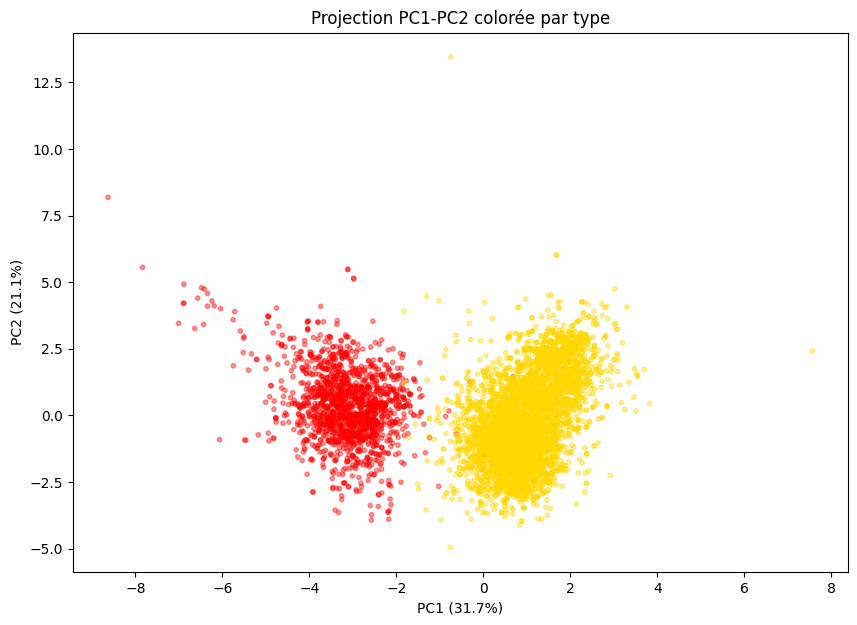

In [20]:
# Scatterplot coloré par type

plt.figure(figsize=(10, 7))
colors = df['type'].map({'red': 'red', 'white': 'gold'})
plt.scatter(X_pca_5[:, 0], X_pca_5[:, 1],
            c=colors, alpha=0.4, s=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('Projection PC1-PC2 colorée par type')
plt.show()

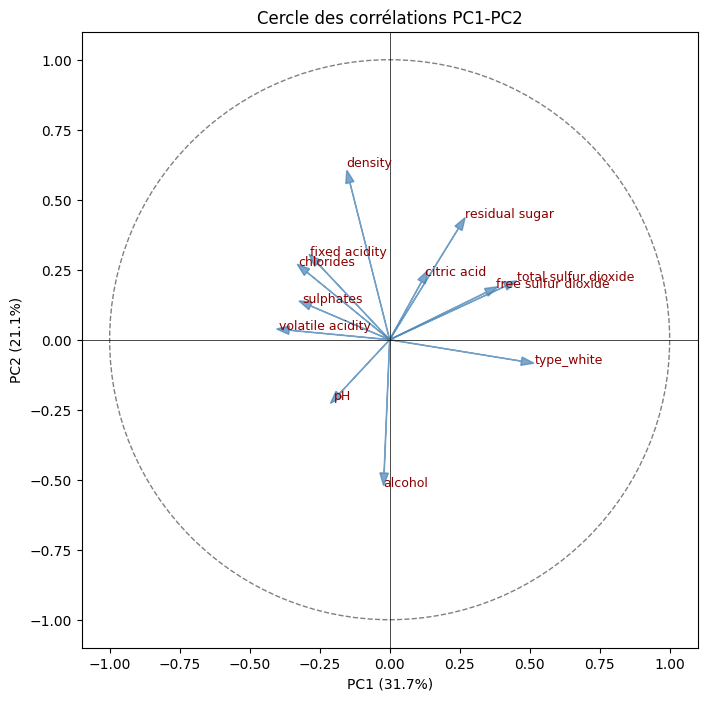

In [21]:
## Le cercle des correlation pour visualiser les loadings de PC1 et PC2. 
## le but et de voir comment chaque variable se positionne dans le plan

fig, ax = plt.subplots(figsize=(8, 8))

# Cercle unité
circle = plt.Circle((0, 0), 1, fill=False, color='gray', ls='--')
ax.add_patch(circle)

# Flèches pour chaque variable
for i, var in enumerate(X.columns):
    ax.arrow(0, 0,
             loadings['PC1'].iloc[i],
             loadings['PC2'].iloc[i],
             head_width=0.03, color='steelblue', alpha=0.7)
    ax.text(loadings['PC1'].iloc[i]*1.1,
            loadings['PC2'].iloc[i]*1.1,
            var, fontsize=9, color='darkred')

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axhline(0, color='black', lw=0.5)
ax.axvline(0, color='black', lw=0.5)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Cercle des corrélations PC1-PC2')
ax.set_aspect('equal')
plt.show()

### Point clés
type_white et alcohol sont quasiment opposés sur PC1-PC2: un vin blanc est rarement très alcoolisé dans ce dataset.

density et alcohol sont opposés sur PC2 : logique chimique (alcool moins dense que l'eau).

residual sugar et density pointent dans la même direction (haut-droite) : cohérent, le sucre alourdit le vin.

pH et fixed acidity s'opposent (bas-gauche vs haut-gauche) : plus d'acide = pH bas, logique.

Variables proches du centre (sulphates, volatile acidity, citric acid) : mal représentées sur PC1-PC2. Leur info est captée par PC3/PC4/PC5.

### Dans ces prochaines étapes nous allons scindés le dataset en deux (Rouge & Blanc) pour voir d'une manière plus détaillée les axes de différenciations

## ACP sur les Rouges

In [22]:
# Filtrer uniquement les rouges 
df_red = df[df['type'] =='red'].copy()

print(df_red.shape)
print(df_red['quality'].value_counts().sort_index())
df_red.head()

(1599, 13)
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [23]:
# Préparation de X_red et y_red pour l'ACP
X_red = df_red.drop(columns = ['quality', 'type'])
y_red = df_red['quality']

# Standarisation de X_red
from sklearn.preprocessing import StandardScaler
scaller_red = StandardScaler()

X_red_scaller = scaller_red.fit_transform(X_red)
print(X_red_scaller.mean().round(1))
print(X_red_scaller.std().round(1))

# ACP sur les rouges

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

pca_red = PCA()
X_red_pca = pca_red.fit_transform(X_red_scaller)

print(X_red_pca.shape)
print(pca_red.explained_variance_ratio_.round(3))
print('')
print("Cumulé :", np.cumsum(pca_red.explained_variance_ratio_).round(3))

-0.0
1.0
(1599, 11)
[0.282 0.175 0.141 0.11  0.087 0.06  0.053 0.038 0.031 0.016 0.005]

Cumulé : [0.282 0.457 0.598 0.708 0.795 0.855 0.908 0.947 0.978 0.995 1.   ]


### Observation clé : les rouges sont moins structurés que le dataset complet

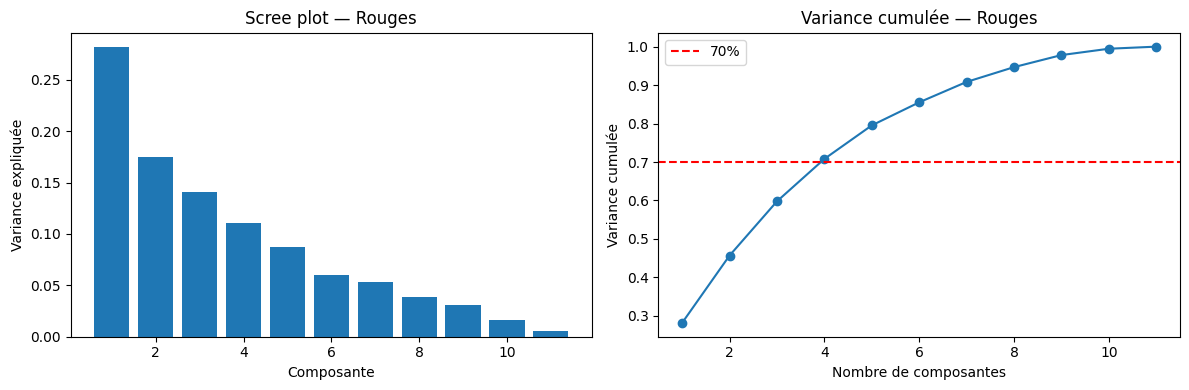

In [24]:
# Mise en place du screenplot des rouge

cumsum_red = np.cumsum(pca_red.explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
ax[0].bar(range(1, 12), pca_red.explained_variance_ratio_)
ax[0].set_xlabel('Composante')
ax[0].set_ylabel('Variance expliquée')
ax[0].set_title('Scree plot — Rouges')
# Variance cumulée
ax[1].plot(range(1, 12), cumsum_red, marker='o')
ax[1].axhline(0.7, ls='--', c='r', label='70%')
ax[1].set_xlabel('Nombre de composantes')
ax[1].set_ylabel('Variance cumulée')
ax[1].set_title('Variance cumulée — Rouges')
ax[1].legend()

plt.tight_layout()
plt.show()

### Nous garderons que les 4 composantes

In [26]:
# Intetpretations des loading rouges par composannte principale
loadings_red = pd.DataFrame(
    pca_red.components_[:4].T,
    columns=['PC1', 'PC2', 'PC3', 'PC4'],
    index=X_red.columns
)

In [27]:
# Pour la première composante principale
loadings_red['PC1'].sort_values(key=abs, ascending=False).round(2)

fixed acidity           0.49
citric acid             0.46
pH                     -0.44
density                 0.40
sulphates               0.24
volatile acidity       -0.24
chlorides               0.21
residual sugar          0.15
alcohol                -0.11
free sulfur dioxide    -0.04
total sulfur dioxide    0.02
Name: PC1, dtype: float64

### Interprétation
PC1 des rouges oppose deux profils :

Côté positif  vin acide, structuré, dense : acidité fixe + citrique élevées, pH bas, densité haute

Côté négatif  vin souple, moins acide : peu d'acides fixes, pH plus haut

PC1 = axe "acidité / structure" des rouges.

Différence majeure avec le dataset complet : PC1 n'est plus dominé par le type. Ici, c'est un vrai axe chimique :

In [28]:
# Nous passons à PC2
print(loadings_red['PC2'].sort_values(key=abs, ascending=False).round(2))

total sulfur dioxide    0.57
free sulfur dioxide     0.51
alcohol                -0.39
volatile acidity        0.27
residual sugar          0.27
density                 0.23
citric acid            -0.15
chlorides               0.15
fixed acidity          -0.11
sulphates              -0.04
pH                      0.01
Name: PC2, dtype: float64


### Interprétation
PC2 oppose deux profils :

Côté positif  vin très sulfité, peu alcoolisé, un peu plus sucré/dense

Côté négatif  vin peu sulfité, plus alcoolisé

👉 PC2 = axe "SO2 / conservation".

Différence avec le dataset complet :

Complet  PC2 = moelleux vs sec (densité/sucre/alcool)

Rouges  PC2 = SO2 vs alcool

Point important : le SO2 total et libre montent ensemble (+0.57 et +0.51), ce qui est cohérent (le free est inclus dans le total). Ils dominent largement PC2 → cet axe capte surtout la quantité de sulfites ajoutés pour la conservation.

Nuance : alcohol (-0.39) s'oppose au SO2 → les vins rouges plus alcoolisés sont moins sulfités. Interprétation œnologique : l'alcool joue un rôle conservateur naturel, donc moins besoin de SO2.

In [29]:
# Pour la troisième composante principale
print(loadings_red['PC3'].sort_values(key=abs, ascending=False).round(2))

alcohol                 0.47
volatile acidity       -0.45
free sulfur dioxide     0.43
density                -0.34
total sulfur dioxide    0.32
sulphates               0.28
citric acid             0.24
fixed acidity          -0.12
residual sugar          0.10
chlorides              -0.09
pH                      0.06
Name: PC3, dtype: float64


### Interprétation
PC3 oppose deux profils :

Côté positif  vin alcoolisé, léger, peu volatile, sulfité (vin "qualité")

Côté négatif  vin peu alcoolisé, dense, avec de l'acidité volatile

PC3 = axe "qualité perçue" des rouges.

Pourquoi ? Regarde les variables qui montent (+) :

alcohol  corrélé positivement à la qualité dans la littérature œnologique

volatile acidity  la VA est un défaut (goût de vinaigre), pénalise la qualité

density vin plus léger, moins concentré

Ces trois variables sont exactement celles qui corrèlent avec quality dans le dataset des rouges.

Nuance : free SO2  est surprenant, mais logique — un vin bien conservé (SO2) garde sa qualité.

In [30]:
# Pour la quatrième composante principale
print(loadings_red['PC4'].sort_values(key=abs, ascending=False).round(2))

chlorides               0.67
sulphates               0.55
residual sugar         -0.37
fixed acidity          -0.23
density                -0.17
alcohol                -0.12
citric acid            -0.08
volatile acidity        0.08
free sulfur dioxide    -0.04
total sulfur dioxide   -0.03
pH                     -0.00
Name: PC4, dtype: float64


### Interprétation
PC4 oppose deux profils :

Côté positif vin salé, riche en sulphates, peu sucré

Côté négatif  vin peu salé, peu de sulphates, un peu sucré

PC4 = axe "minéralité / additifs" des rouges.

Deux blocs dans cet axe :

chlorides + sulphates montent ensemble → les deux sont liés à la minéralité et au traitement œnologique

residual sugar s'oppose → un vin plus sucré est souvent moins salé (style différent)

Nuance : cet axe capte surtout une variation de terroir / traitement (sel + sulphates), moins une caractéristique sensorielle directe.

## ACP sur les blancs

In [31]:
# Nous allons d'abord scinder 
df_white = df[df['type'] == 'white'].copy()
print( 'La dimession de la base de données est : ' ,df_white.shape)
print(df_white['quality'].value_counts().sort_index().reset_index())
df_white.head()

La dimession de la base de données est :  (4898, 13)
   quality  count
0        3     20
1        4    163
2        5   1457
3        6   2198
4        7    880
5        8    175
6        9      5


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
1599,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1600,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
1601,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
1602,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white
1603,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


In [32]:
# preparation des sonnées pour l'ACP
y_white = df_white['quality']
X_white = df_white.drop(columns=['quality', 'type'])

print(X_white.shape)
print('')
print(X_white.columns.tolist())

(4898, 11)

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [33]:
# Standarison les variables
from sklearn.preprocessing import StandardScaler
scaller_white = StandardScaler()
X_white_scaller = scaller_white.fit_transform(X_white)

# ACP sur le vin blanc
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

pca_white = PCA()
X_white_pca = pca_white.fit_transform(X_white_scaller)

print(X_white_pca.shape)
print(pca_white.explained_variance_ratio_.round(3))
print('')
print("Cumulé :", np.cumsum(pca_white.explained_variance_ratio_).round(3))

(4898, 11)
[0.293 0.143 0.111 0.093 0.088 0.085 0.066 0.054 0.038 0.026 0.002]

Cumulé : [0.293 0.436 0.547 0.64  0.728 0.814 0.88  0.934 0.972 0.998 1.   ]


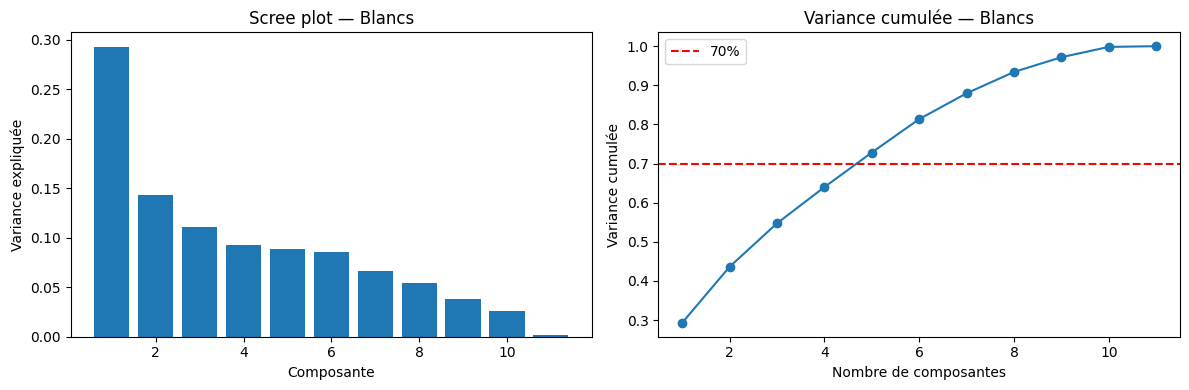

In [34]:
# Le screenplot des blancs
import matplotlib.pyplot as plt

cumsum_white = np.cumsum(pca_white.explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
ax[0].bar(range(1, 12), pca_white.explained_variance_ratio_)
ax[0].set_xlabel('Composante')
ax[0].set_ylabel('Variance expliquée')
ax[0].set_title('Scree plot — Blancs')

# Variance cumulée
ax[1].plot(range(1, 12), cumsum_white, marker='o')
ax[1].axhline(0.7, ls='--', c='r', label='70%')
ax[1].set_xlabel('Nombre de composantes')
ax[1].set_ylabel('Variance cumulée')
ax[1].set_title('Variance cumulée — Blancs')
ax[1].legend()

plt.tight_layout()
plt.show()

In [35]:
# Affichage des loadings par composantes principales

loadings_white = pd.DataFrame(
    pca_white.components_[:5].T,
    columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'],
    index=X_white.columns
)

In [36]:
# Pour la première composante
print(loadings_white['PC1'].sort_values(key=abs, ascending=False).round(2))

density                 0.51
alcohol                -0.44
residual sugar          0.43
total sulfur dioxide    0.41
free sulfur dioxide     0.30
chlorides               0.21
fixed acidity           0.16
citric acid             0.14
pH                     -0.13
sulphates               0.04
volatile acidity        0.01
Name: PC1, dtype: float64


### Interprétation
PC1 des blancs oppose deux profils :

Côté positif  vin dense, sucré, peu alcoolisé, très sulfité

Côté négatif  vin léger, sec, plus alcoolisé, peu sulfité

PC1 = axe "moelleux vs sec" des blancs 

Cohérence chimique :

Sucre densité 

Sucre  alcool (le sucre non fermenté reste, donc moins transformé en alcool)

SO2  plus de conservateur (les vins sucrés se conservent moins bien sans sulfites)

Différence avec les rouges : chez les rouges, PC1 était acidité/structure. Chez les blancs, PC1 est moelleux vs sec. Les blancs se différencient d'abord par leur taux de sucre, pas par leur acidité.

In [77]:
# Pour la deuxième composante principale
print(loadings_white['PC2'].sort_values(key=abs, ascending=False).round(2))

fixed acidity           0.59
pH                     -0.58
citric acid             0.35
free sulfur dioxide    -0.29
total sulfur dioxide   -0.24
sulphates              -0.22
volatile acidity       -0.05
alcohol                 0.04
chlorides               0.01
residual sugar         -0.01
density                -0.01
Name: PC2, dtype: float64


### Interprétation
PC2 des blancs oppose deux profils :

Côté positif  vin très acide (fixed acidity + citrique élevés, pH bas), peu sulfité

Côté négatif vin peu acide (pH élevé), plus sulfité

PC2 = axe "acidité" des blancs.

Le duo fixed acidity (+0.59) / pH (-0.58) est le cœur de cet axe — c'est une opposition chimique pure : plus tu as d'acide fixe, plus le pH baisse.

Lien inverse avec le SO2 : les vins plus acides sont moins sulfités. Interprétation œnologique : l'acidité joue un rôle conservateur naturel, donc moins besoin de SO2.

Différence avec les rouges :

Rouges PC1 était déjà l'acidité

Blancs l'acidité arrive en PC2 (car PC1 est dominé par le sucre)

In [37]:
# Passons à la troisième composante 
print(loadings_white['PC3'].sort_values(key=abs, ascending=False).round(2))

volatile acidity        0.59
citric acid            -0.50
sulphates              -0.43
free sulfur dioxide    -0.28
residual sugar          0.21
density                 0.13
pH                     -0.13
total sulfur dioxide   -0.12
fixed acidity          -0.12
alcohol                -0.11
chlorides               0.10
Name: PC3, dtype: float64


Interprétation
PC3 des blancs oppose deux profils :

Côté positif vin avec défaut : acidité volatile élevée (vinaigre), peu de citrique, peu de sulphates

Côté négatif  vin sain : peu de volatile, riche en citrique et sulphates

PC3 = axe "défaut vs qualité" des blancs.

Logique œnologique :

volatile acidity  = défaut (goût de vinaigre, pénalise la qualité)

citric acid  = moins de fraîcheur

sulphates  = moins d'additif stabilisant

Ces trois variables bougent ensemble → elles décrivent un vin mal maîtrisé.

Différence avec les rouges :

Rouges PC3 = qualité via alcohol + volatile acidity

Blancs PC3 = qualité via volatile acidity + citric acid + sulphates

Chez les blancs, l'acidité volatile est le marqueur central du défaut , mais l'alcool ne joue pas ici.

In [38]:
# Pour quatrième composante
print(loadings_white['PC4'].sort_values(key=abs, ascending=False).round(2))

chlorides               0.71
sulphates               0.44
free sulfur dioxide    -0.31
volatile acidity        0.27
residual sugar         -0.27
citric acid             0.15
alcohol                -0.14
pH                      0.10
total sulfur dioxide   -0.06
density                -0.02
fixed acidity           0.02
Name: PC4, dtype: float64


### Interprétation
PC4 des blancs oppose deux profils :

Côté positif  vin salé, riche en sulphates, peu sucré

Côté négatif vin peu salé, peu de sulphates, plus sucré

PC4 = axe "minéralité / additifs" des blancs.

Similitude frappante avec les rouges : chez les rouges, PC4 était aussi chlorides + sulphates → même axe de différenciation ! C'est un résultat remarquable :

Peu importe le type (rouge/blanc), la minéralité est le 4ᵉ axe de différenciation

chlorides (+0.71 blancs, +0.67 rouges) et sulphates (+0.44 blancs, +0.55 rouges) dominent dans les deux cas

Nuance : chez les blancs, free SO2 (-0.31) et residual sugar (-0.27) s'ajoutent en opposition → les vins blancs salés/sulfatés sont aussi moins sucrés.

In [40]:
# Pour la cinquième composante
print(loadings_white['PC5'].sort_values(key = abs, ascending = False).round(2))

volatile acidity        0.64
sulphates               0.40
alcohol                 0.34
chlorides              -0.33
total sulfur dioxide    0.29
fixed acidity           0.25
free sulfur dioxide     0.18
pH                     -0.12
density                -0.08
citric acid             0.05
residual sugar          0.01
Name: PC5, dtype: float64


### Interprétation
PC5 des blancs oppose deux profils :

Côté positif vin avec volatile + sulphates + alcool, peu salé

Côté négatif vin peu volatile, peu sulfaté, plus salé

PC5 = axe "défaut résiduel / profil atypique" des blancs.

Nuance importante : volatile acidity revient ici (+0.64) alors qu'elle était déjà sur PC3 (+0.59). Deux interprétations possibles :

PC3 capte le volatile opposé à citrique/sulphates (axe "défaut vs fraîcheur")

PC5 capte le volatile lié à sulphates/alcool (axe "défaut résiduel" différent)

PC5 explique seulement 6% de variance → axe secondaire, à interpréter avec prudence. C'est le signe que les blancs ont une structure plus diffuse.



### Visualisation

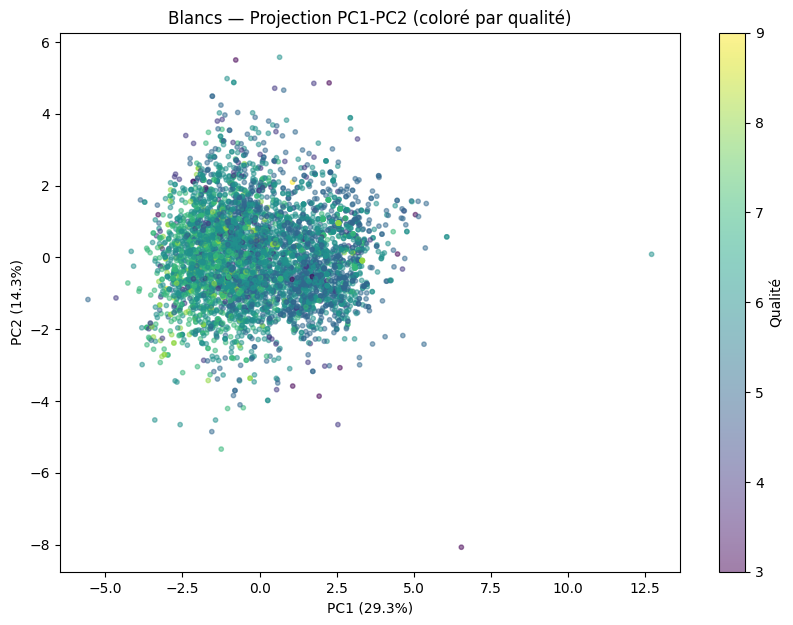

In [42]:
# Visualisation du scatter sur PC1 et PC2 coloré par qualité

X_pca_white_5 = X_white_pca[:,:5]

plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca_white_5[:,0], X_pca_white_5[:,1], c = y_white, cmap = 'viridis', alpha = 0.5, s = 10)

plt.colorbar(scatter,label = 'Qualité')
plt.xlabel(f'PC1 ({pca_white.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca_white.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('Blancs — Projection PC1-PC2 (coloré par qualité)')
plt.show()

### Toutes les couleurs sont confondues PC1 et PC2 captent la structure chimique (moelleux, acidité) mais pas la qualité.

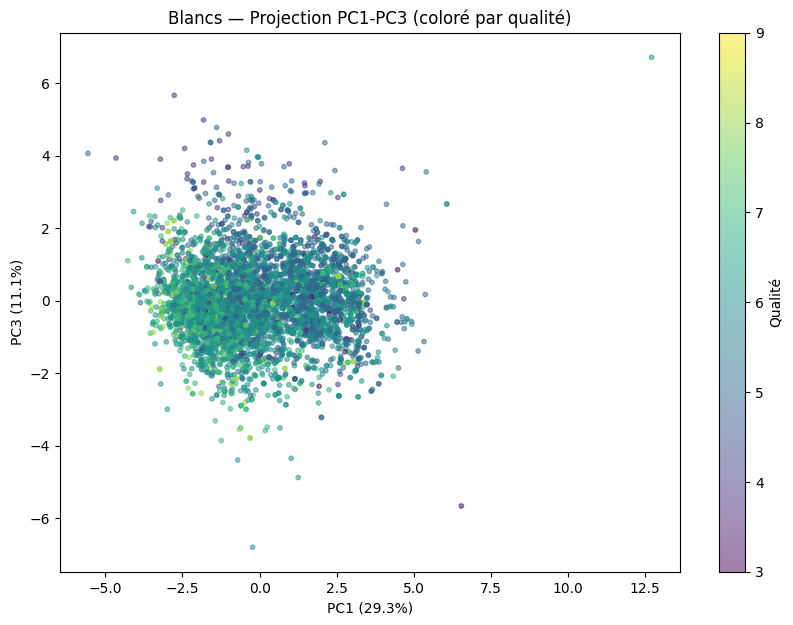

In [44]:
# Scatter sur PC1 et PC2 

plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca_white_5[:,0], X_pca_white_5[:,2], c = y_white, cmap = 'viridis', alpha = 0.5, s = 10)

plt.colorbar(scatter, label='Qualité')
plt.xlabel(f'PC1 ({pca_white.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC3 ({pca_white.explained_variance_ratio_[2]*100:.1f}%)')
plt.title('Blancs — Projection PC1-PC3 (coloré par qualité)')
plt.show()

### PC3 ne capte pas aussi la qualité. Pour être nous aalons mettre en palce un test de corrélation entre PC3 et la qualité des vins blancs

In [45]:
from scipy.stats import pearsonr

for i in range(5):
    r, p = pearsonr(X_pca_white_5[:, i], y_white)
    print(f"PC{i+1} vs qualité : r = {r:.3f}, p = {p:.2e}")

PC1 vs qualité : r = -0.297, p = 2.78e-100
PC2 vs qualité : r = -0.058, p = 4.71e-05
PC3 vs qualité : r = -0.218, p = 6.64e-54
PC4 vs qualité : r = -0.191, p = 2.36e-41
PC5 vs qualité : r = 0.047, p = 9.69e-04


### Interpretation
La qualité est corrélée à plusieurs axes, mais aucun fortement. Le maximum est r = -0.297 la qualité est multi-factorielle et diffuse.
La qualité n'est pas réductible à un seul axe chimique
Elle dépend de plusieurs dimensions simultanément (alcool, volatile, sucre…)

### Cercle des corrélations (vins blancs)

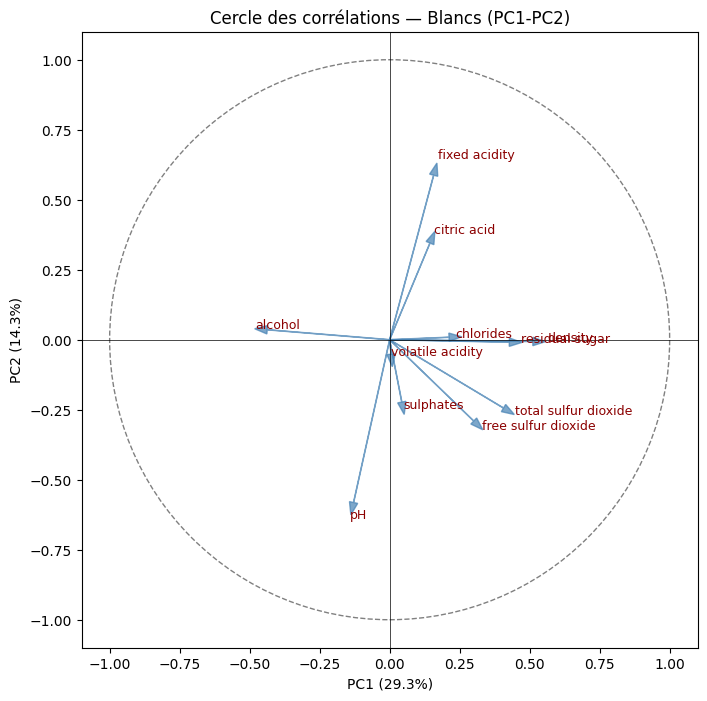

In [46]:
fig, ax = plt.subplots(figsize=(8, 8))

circle = plt.Circle((0, 0), 1, fill=False, color='gray', ls='--')
ax.add_patch(circle)

for i, var in enumerate(X_white.columns):
    ax.arrow(0, 0,
             loadings_white['PC1'].iloc[i],
             loadings_white['PC2'].iloc[i],
             head_width=0.03, color='steelblue', alpha=0.7)
    ax.text(loadings_white['PC1'].iloc[i]*1.1,
            loadings_white['PC2'].iloc[i]*1.1,
            var, fontsize=9, color='darkred')

ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.axhline(0, color='black', lw=0.5); ax.axvline(0, color='black', lw=0.5)
ax.set_xlabel(f'PC1 ({pca_white.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_white.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Cercle des corrélations — Blancs (PC1-PC2)')
ax.set_aspect('equal')
plt.show()

# Conclusion : Analyse du profil des vins par ACP

## 1. Rappel de l'objectif

Ce projet visait à identifier les **axes clés de différenciation** entre vins à partir de leurs propriétés chimiques, en utilisant l'**Analyse en Composantes Principales (ACP)**. La problématique métier — transposée du vin vers la segmentation client  était : *quels sont les axes qui structurent le plus les profils, et peut-on identifier des groupes significatifs ?*

## 2. Démarche

Le dataset Wine Quality (UCI) regroupe **6497 vins** (1599 rouges, 4898 blancs) décrits par **11 variables chimiques** (acidités, sucres, SO2, densité, pH, alcool, sulphates, chlorides) et une note de qualité (3 à 9).

Après standardisation, une ACP a été menée en **trois temps** :
1. Sur le dataset complet
2. Sur les rouges seuls
3. Sur les blancs seuls

Cette séparation s'est révélée **essentielle** : la structure chimique des rouges et des blancs diffère fondamentalement, et l'analyse conjointe masquait cette réalité.

## 3. Résultats principaux

**Sur le dataset complet (5 axes, 79.9% de variance)** : le premier axe (31.7%) oppose les **vins blancs aux rouges**, captant plus d'information que toute autre dimension chimique. Les axes suivants décrivent le style (moelleux/sec), l'acidité, la conservation et la minéralité.

**Sur les rouges (4 axes, 70.8%)** : la différenciation repose d'abord sur l'**acidité et la structure** (acidité fixe, citrique, pH, densité), puis sur la **conservation (SO2)**, la **qualité perçue** (alcool, acidité volatile) et la **minéralité**.

**Sur les blancs (5 axes, ~80%)** : le premier axe est le **degré de moelleux** (sucre, densité, alcool), suivi de l'**acidité**, du **défaut œnologique** (acidité volatile), de la **minéralité** et d'un axe résiduel.

## 4. Enseignements majeurs

1. **La structure chimique diffère selon le type** : rouges et blancs ne se différencient pas selon les mêmes axes. Toute analyse globale doit donc être **stratifiée**.
2. **La minéralité** (chlorures + sulphates) constitue un axe **universel**, présent chez les deux types.
3. **La qualité n'est jamais le premier axe** : elle apparaît systématiquement en position secondaire (PC3), et les corrélations entre composantes et qualité restent **faibles** (|r| max ≈ 0.30). L'ACP ne permet donc **pas de prédire la qualité** : elle révèle la structure chimique, pas la note de dégustation.
4. **L'acidité volatile** est le seul marqueur **commun et robuste** d'un défaut, dans les deux types de vins.

## 5. Réponse à la problématique

Les axes de différenciation s'organisent en **trois niveaux** :

- **Niveau 1 — Type** : blanc vs rouge (dominant dans l'analyse conjointe).
- **Niveau 2 — Style** : acidité/structure pour les rouges, moelleux/sucre pour les blancs.
- **Niveau 3 — Attributs transverses** : minéralité, conservation (SO2), défaut (acidité volatile).

Transposé au cas client, cela signifie qu'une segmentation efficace devrait d'abord distinguer des **catégories de clients** (équivalent du type), puis analyser leur **style comportemental** (équivalent du moelleux/acidité), et enfin mobiliser des **signaux universels** (satisfaction, fidélité).

## 6. Limites et perspectives

L'ACP étant une méthode **linéaire**, elle ne capte pas les relations non-linéaires entre variables, ce qui explique en partie la faible séparation de la qualité. Deux prolongements naturels s'imposent : un **clustering** (K-means, DBSCAN) sur les composantes pour identifier des segments concrets, et un **modèle supervisé** (Random Forest, XGBoost) pour prédire la qualité à partir des variables chimiques.